In [1]:
import json
from pathlib import Path

import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

PROCESSED_DIR = Path("/content/drive/MyDrive/tastelet/data/processed")

train_df = pd.read_csv(PROCESSED_DIR / "ratings_train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "ratings_val.csv")
test_df = pd.read_csv(PROCESSED_DIR / "ratings_test.csv")
n_movies = len(json.loads((PROCESSED_DIR / "movie2idx.json").read_text()))

print(train_df.shape, val_df.shape, test_df.shape, n_movies)

Mounted at /content/drive
(72088, 6) (9011, 6) (9012, 6) 3636


In [2]:
import torch
from torch.utils.data import Dataset

class RatingsDataset(Dataset):
    def __init__(self, ratings_df: pd.DataFrame) -> None:
        # Tensors built once here, so __getitem__ is just indexing.
        self.user_ids = torch.tensor(ratings_df["user_idx"].to_numpy(), dtype=torch.long)
        self.movie_ids = torch.tensor(ratings_df["movie_idx"].to_numpy(), dtype=torch.long)
        self.ratings = torch.tensor(ratings_df["rating"].to_numpy(), dtype=torch.float32)

    def __len__(self) -> int:
        return len(self.ratings)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        return self.user_ids[i], self.movie_ids[i], self.ratings[i]

train_dataset = RatingsDataset(train_df)
print(len(train_dataset), train_dataset[0])

72088 (tensor(102), tensor(751), tensor(4.))


In [3]:
from torch.utils.data import DataLoader

SEED = 42
BATCH_SIZE = 256

torch.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(RatingsDataset(val_df), batch_size=BATCH_SIZE, shuffle=False)

user_batch, movie_batch, rating_batch = next(iter(train_loader))
print(len(train_loader), user_batch.shape, rating_batch.shape)

282 torch.Size([256]) torch.Size([256])


In [4]:
from torch import nn

n_users = int(train_df["user_idx"].max()) + 1
EMBEDDING_DIM = 32
DROPOUT = 0.2

class NCF(nn.Module):
    def __init__(self, n_users: int, n_movies: int, dim: int, dropout: float) -> None:
        super().__init__()
        self.user_embedding = nn.Embedding(n_users, dim)
        self.movie_embedding = nn.Embedding(n_movies, dim)
        self.mlp = nn.Sequential(
            nn.Linear(2 * dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, user_ids: torch.Tensor, movie_ids: torch.Tensor) -> torch.Tensor:
        pair = torch.cat([self.user_embedding(user_ids), self.movie_embedding(movie_ids)], dim=1)
        return self.mlp(pair).squeeze(-1)

torch.manual_seed(SEED)
model = NCF(n_users, n_movies, EMBEDDING_DIM, DROPOUT)
print(model(user_batch, movie_batch).shape)

torch.Size([256])


In [5]:
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def train_one_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer) -> float:
    model.train()
    total_loss = 0.0
    for user_ids, movie_ids, ratings in loader:
        optimizer.zero_grad()
        loss = loss_fn(model(user_ids, movie_ids), ratings)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(ratings)
    return total_loss / len(loader.dataset)

def evaluate_rmse(model: nn.Module, loader: DataLoader) -> float:
    model.eval()
    squared_error = 0.0
    with torch.no_grad():
        for user_ids, movie_ids, ratings in loader:
            squared_error += ((model(user_ids, movie_ids) - ratings) ** 2).sum().item()
    return (squared_error / len(loader.dataset)) ** 0.5

print("val RMSE before training:", evaluate_rmse(model, val_loader))
print("train loss, epoch 1:", train_one_epoch(model, train_loader, optimizer))
print("val RMSE after 1 epoch:", evaluate_rmse(model, val_loader))

val RMSE before training: 3.5497154111572398
train loss, epoch 1: 2.3325515422978738
val RMSE after 1 epoch: 1.0026754927919155


In [6]:
import copy

MAX_EPOCHS = 20

torch.manual_seed(SEED)
model = NCF(n_users, n_movies, EMBEDDING_DIM, DROPOUT)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

history = []
best_val_rmse = float("inf")
best_state = None

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer)
    val_rmse = evaluate_rmse(model, val_loader)
    history.append({"epoch": epoch, "train_rmse": train_loss**0.5, "val_rmse": val_rmse})
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_state = copy.deepcopy(model.state_dict())
    print(f"epoch {epoch:2d}  train {train_loss**0.5:.4f}  val {val_rmse:.4f}")

print("best val RMSE:", best_val_rmse)

epoch  1  train 1.5227  val 0.9945
epoch  2  train 1.0972  val 0.9543
epoch  3  train 1.0572  val 0.9275
epoch  4  train 1.0262  val 0.9207
epoch  5  train 1.0083  val 0.9052
epoch  6  train 0.9917  val 0.8968
epoch  7  train 0.9783  val 0.8905
epoch  8  train 0.9638  val 0.8836
epoch  9  train 0.9483  val 0.8798
epoch 10  train 0.9371  val 0.8741
epoch 11  train 0.9264  val 0.8685
epoch 12  train 0.9188  val 0.8678
epoch 13  train 0.9083  val 0.8618
epoch 14  train 0.8992  val 0.8586
epoch 15  train 0.8921  val 0.8584
epoch 16  train 0.8841  val 0.8549
epoch 17  train 0.8775  val 0.8564
epoch 18  train 0.8701  val 0.8527
epoch 19  train 0.8639  val 0.8552
epoch 20  train 0.8551  val 0.8508
best val RMSE: 0.8507775633785839


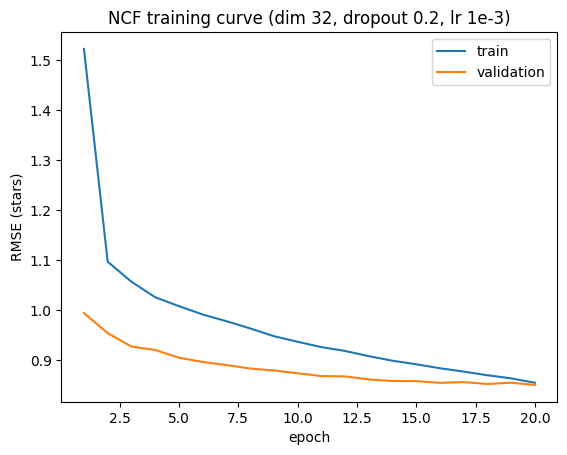

In [7]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

plt.plot(history_df["epoch"], history_df["train_rmse"], label="train")
plt.plot(history_df["epoch"], history_df["val_rmse"], label="validation")
plt.xlabel("epoch")
plt.ylabel("RMSE (stars)")
plt.title("NCF training curve (dim 32, dropout 0.2, lr 1e-3)")
plt.legend()
plt.show()

In [8]:
def train_ncf(
    train_dataset: Dataset, dim: int, dropout: float, lr: float
) -> tuple[float, dict, list[dict]]:
    torch.manual_seed(SEED)
    model = NCF(n_users, n_movies, dim, dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

    history = []
    best_val_rmse, best_state = float("inf"), None
    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_one_epoch(model, loader, optimizer)
        val_rmse = evaluate_rmse(model, val_loader)
        history.append({"epoch": epoch, "train_rmse": train_loss**0.5, "val_rmse": val_rmse})
        if val_rmse < best_val_rmse:
            best_val_rmse, best_state = val_rmse, copy.deepcopy(model.state_dict())
    return best_val_rmse, best_state, history

best_val_rmse, best_state, history = train_ncf(train_dataset, EMBEDDING_DIM, DROPOUT, LEARNING_RATE)
print(best_val_rmse)

0.8502882027616603


In [9]:
second_val_rmse, _, _ = train_ncf(train_dataset, EMBEDDING_DIM, DROPOUT, LEARNING_RATE)
print(best_val_rmse, second_val_rmse, best_val_rmse == second_val_rmse)

0.8502882027616603 0.8502882027616603 True


In [10]:
DEFAULT_SETTINGS = {"dim": EMBEDDING_DIM, "dropout": DROPOUT, "lr": LEARNING_RATE}
tuning_changes = [{}, {"dim": 16}, {"dim": 64}, {"dropout": 0.1}, {"dropout": 0.3}, {"lr": 1e-2}]

tuning_rows = []
for change in tuning_changes:
    settings = {**DEFAULT_SETTINGS, **change}
    val_rmse, _, run_history = train_ncf(train_dataset, **settings)
    best_epoch = min(run_history, key=lambda row: row["val_rmse"])["epoch"]
    tuning_rows.append({**settings, "best_val_rmse": round(val_rmse, 4), "best_epoch": best_epoch})
    print(tuning_rows[-1])

tuning_df = pd.DataFrame(tuning_rows)
tuning_df

{'dim': 32, 'dropout': 0.2, 'lr': 0.001, 'best_val_rmse': 0.8503, 'best_epoch': 20}
{'dim': 16, 'dropout': 0.2, 'lr': 0.001, 'best_val_rmse': 0.8583, 'best_epoch': 20}
{'dim': 64, 'dropout': 0.2, 'lr': 0.001, 'best_val_rmse': 0.8529, 'best_epoch': 18}
{'dim': 32, 'dropout': 0.1, 'lr': 0.001, 'best_val_rmse': 0.8518, 'best_epoch': 20}
{'dim': 32, 'dropout': 0.3, 'lr': 0.001, 'best_val_rmse': 0.8501, 'best_epoch': 20}
{'dim': 32, 'dropout': 0.2, 'lr': 0.01, 'best_val_rmse': 0.8478, 'best_epoch': 6}


,dim,dropout,lr,best_val_rmse,best_epoch
0,32,0.2,0.001,0.8503,20
1,16,0.2,0.001,0.8583,20
2,64,0.2,0.001,0.8529,18
3,32,0.1,0.001,0.8518,20
4,32,0.3,0.001,0.8501,20
5,32,0.2,0.010,0.8478,6


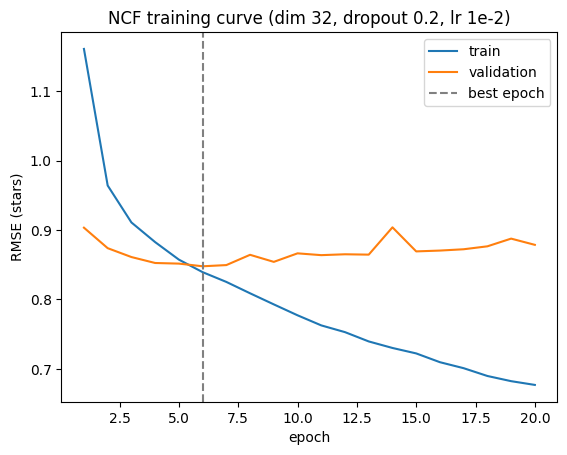

0.8478356309986891


In [11]:
FINAL_LR = 1e-2

best_val_rmse, best_state, history = train_ncf(train_dataset, EMBEDDING_DIM, DROPOUT, FINAL_LR)
model = NCF(n_users, n_movies, EMBEDDING_DIM, DROPOUT)
model.load_state_dict(best_state)
model.eval()

history_df = pd.DataFrame(history)
plt.plot(history_df["epoch"], history_df["train_rmse"], label="train")
plt.plot(history_df["epoch"], history_df["val_rmse"], label="validation")
plt.axvline(6, linestyle="--", color="gray", label="best epoch")
plt.xlabel("epoch")
plt.ylabel("RMSE (stars)")
plt.title("NCF training curve (dim 32, dropout 0.2, lr 1e-2)")
plt.legend()
plt.show()

print(best_val_rmse)

In [12]:
import numpy as np

def rmse(model_predict, test_df: pd.DataFrame) -> float:
    predicted = model_predict(test_df["user_idx"].to_numpy(), test_df["movie_idx"].to_numpy())
    errors = predicted - test_df["rating"].to_numpy()
    return float(np.sqrt(np.mean(errors**2)))

TOP_K = 10
LIKED_RATING = 4.0

def hit_at_10(score_fn, train_df, test_df) -> float:
    """Share of test users with at least one liked test movie in their top 10."""
    seen_by_user = train_df.groupby("user_idx")["movie_idx"].apply(set)
    liked = test_df[test_df["rating"] >= LIKED_RATING]
    liked_by_user = liked.groupby("user_idx")["movie_idx"].apply(set)

    hits = 0
    for user_idx, liked_movies in liked_by_user.items():
        scores = np.asarray(score_fn(user_idx), dtype=float).copy()
        seen = list(seen_by_user.get(user_idx, set()))
        scores[seen] = -np.inf  # never recommend a movie already rated in train
        top_k = np.argpartition(-scores, TOP_K)[:TOP_K]
        if liked_movies & set(top_k.tolist()):
            hits += 1
    return hits / len(liked_by_user)

MIN_RATING, MAX_RATING = 0.5, 5.0
all_movie_ids = torch.arange(n_movies)

def ncf_predict(user_ids: np.ndarray, movie_ids: np.ndarray) -> np.ndarray:
    with torch.no_grad():
        predicted = model(torch.as_tensor(user_ids), torch.as_tensor(movie_ids)).numpy()
    return np.clip(predicted, MIN_RATING, MAX_RATING)

def ncf_scores(user_idx: int) -> np.ndarray:
    with torch.no_grad():
        return model(torch.full((n_movies,), user_idx), all_movie_ids).numpy()

ncf_test_rmse = rmse(ncf_predict, test_df)
ncf_test_hit = hit_at_10(ncf_scores, train_df, test_df)
print(f"NCF test RMSE {ncf_test_rmse:.4f}  Hit@10 {ncf_test_hit:.4f}")

NCF test RMSE 0.8662  Hit@10 0.1063


In [13]:
rating_counts = np.bincount(train_df["movie_idx"], minlength=n_movies)

def top_10_rating_counts(score_fn, user_idx: int) -> np.ndarray:
    scores = np.asarray(score_fn(user_idx), dtype=float).copy()
    scores[train_df.loc[train_df.user_idx == user_idx, "movie_idx"]] = -np.inf
    top_10 = np.argpartition(-scores, TOP_K)[:TOP_K]
    return rating_counts[top_10]

for user_idx in [0, 1, 2]:
    print(user_idx, "NCF:", sorted(top_10_rating_counts(ncf_scores, user_idx)))

print("median ratings per movie overall:", np.median(rating_counts))

0 NCF: [np.int64(5), np.int64(5), np.int64(5), np.int64(6), np.int64(8), np.int64(10), np.int64(13), np.int64(20), np.int64(21), np.int64(106)]
1 NCF: [np.int64(5), np.int64(5), np.int64(7), np.int64(9), np.int64(10), np.int64(20), np.int64(21), np.int64(28), np.int64(192), np.int64(250)]
2 NCF: [np.int64(7), np.int64(41), np.int64(45), np.int64(114), np.int64(154), np.int64(175), np.int64(192), np.int64(216), np.int64(227), np.int64(250)]
median ratings per movie overall: 10.0


In [14]:
NEGATIVES_PER_RATING = 1
NEGATIVE_RATING = 0.5

def sample_negatives(ratings_df: pd.DataFrame, rng: np.random.Generator) -> pd.DataFrame:
    # One code per (user, movie) pair so "did this user rate it?" is a fast array lookup.
    seen_codes = (ratings_df["user_idx"] * n_movies + ratings_df["movie_idx"]).to_numpy()
    users = np.repeat(ratings_df["user_idx"].to_numpy(), NEGATIVES_PER_RATING)
    movies = rng.integers(0, n_movies, size=len(users))
    clashes = np.isin(users * n_movies + movies, seen_codes)
    while clashes.any():
        movies[clashes] = rng.integers(0, n_movies, size=clashes.sum())
        clashes = np.isin(users * n_movies + movies, seen_codes)
    return pd.DataFrame({"user_idx": users, "movie_idx": movies, "rating": NEGATIVE_RATING})

negatives_df = sample_negatives(train_df, np.random.default_rng(SEED))
overlap = negatives_df.merge(train_df, on=["user_idx", "movie_idx"])
print(len(negatives_df), "negatives,", len(overlap), "overlap with real ratings")

72088 negatives, 0 overlap with real ratings


In [15]:
train_with_negatives_df = pd.concat([train_df, negatives_df], ignore_index=True)
train_with_negatives_dataset = RatingsDataset(train_with_negatives_df)

best_val_rmse, best_state, history = train_ncf(
    train_with_negatives_dataset, EMBEDDING_DIM, DROPOUT, lr=1e-2
)
print(len(train_with_negatives_dataset), best_val_rmse)

144176 1.4245215833205478


In [16]:
model = NCF(n_users, n_movies, EMBEDDING_DIM, DROPOUT)
model.load_state_dict(best_state)
model.eval()

all_movie_ids = torch.arange(n_movies)

def ncf_scores(user_idx: int) -> np.ndarray:
    user_ids = torch.full((n_movies,), user_idx)
    with torch.no_grad():
        return model(user_ids, all_movie_ids).numpy()

print("Hit@10 with negatives:", hit_at_10(ncf_scores, train_df, test_df))

Hit@10 with negatives: 0.3963963963963964


In [17]:
fewer_negatives_df = negatives_df.sample(frac=0.25, random_state=SEED)
train_quarter_neg_dataset = RatingsDataset(pd.concat([train_df, fewer_negatives_df], ignore_index=True))

best_val_rmse, best_state, history = train_ncf(train_quarter_neg_dataset, EMBEDDING_DIM, DROPOUT, lr=1e-2)
print(best_val_rmse)
model = NCF(n_users, n_movies, EMBEDDING_DIM, DROPOUT)
model.load_state_dict(best_state)
model.eval()
print("Hit@10, 0.25 negatives:", hit_at_10(ncf_scores, train_df, test_df))

1.0473380185872183
Hit@10, 0.25 negatives: 0.23063063063063063


In [18]:
MIN_RATINGS_TO_RECOMMEND = 20
rating_counts = np.bincount(train_df["movie_idx"], minlength=n_movies)

best_val_rmse, best_state, history = train_ncf(train_dataset, EMBEDDING_DIM, DROPOUT, lr=1e-2)
model = NCF(n_users, n_movies, EMBEDDING_DIM, DROPOUT)
model.load_state_dict(best_state)
model.eval()

def ncf_scores_min_count(user_idx: int) -> np.ndarray:
    scores = ncf_scores(user_idx)
    scores[rating_counts < MIN_RATINGS_TO_RECOMMEND] = -np.inf
    return scores

print(best_val_rmse)
print("Hit@10 with min-count filter:", hit_at_10(ncf_scores_min_count, train_df, test_df))

0.8478356309986891
Hit@10 with min-count filter: 0.18018018018018017


In [19]:
for min_ratings in [50, 100]:
    MIN_RATINGS_TO_RECOMMEND = min_ratings
    print(min_ratings, hit_at_10(ncf_scores_min_count, train_df, test_df))

50 0.2648648648648649
100 0.3261261261261261


In [20]:
two_neg_rng = np.random.default_rng(SEED)
two_negatives_df = sample_negatives(pd.concat([train_df, train_df], ignore_index=True), two_neg_rng)
train_two_neg_dataset = RatingsDataset(pd.concat([train_df, two_negatives_df], ignore_index=True))

best_val_rmse, best_state, history = train_ncf(train_two_neg_dataset, EMBEDDING_DIM, DROPOUT, lr=1e-2)
model = NCF(n_users, n_movies, EMBEDDING_DIM, DROPOUT)
model.load_state_dict(best_state)
model.eval()

print(len(two_negatives_df))
print("Hit@10, 2 negatives:", hit_at_10(ncf_scores, train_df, test_df))

144176
Hit@10, 2 negatives: 0.4018018018018018


In [21]:
four_neg_rng = np.random.default_rng(SEED)
four_negatives_df = sample_negatives(pd.concat([train_df] * 4, ignore_index=True), four_neg_rng)
train_four_neg_dataset = RatingsDataset(pd.concat([train_df, four_negatives_df], ignore_index=True))

best_val_rmse, best_state, history = train_ncf(train_four_neg_dataset, EMBEDDING_DIM, DROPOUT, lr=1e-2)
model = NCF(n_users, n_movies, EMBEDDING_DIM, DROPOUT)
model.load_state_dict(best_state)
model.eval()

print(len(four_negatives_df))
print("Hit@10, 4 negatives:", hit_at_10(ncf_scores, train_df, test_df))

288352
Hit@10, 4 negatives: 0.4072072072072072


In [24]:
RESULTS_PATH = "/content/drive/MyDrive/tastelet/results/results.csv"

ncf_rows = pd.DataFrame(
    [
        {"model": "ncf_rating", "rmse": round(ncf_test_rmse, 4), "hit_at_10": round(ncf_test_hit, 4)},
        {"model": "ncf_ranking_4neg", "rmse": None, "hit_at_10": round(hit_at_10(ncf_scores, train_df, test_df), 4)},
    ]
)

results = pd.read_csv(RESULTS_PATH)
results = results[~results["model"].isin(ncf_rows["model"])]
results = pd.concat([results, ncf_rows], ignore_index=True)
results.to_csv(RESULTS_PATH, index=False)
results

,model,rmse,hit_at_10
0,global_mean,1.0334,NaN
1,popularity,NaN,0.3856
2,item_knn,0.8582,0.5441
3,ncf_rating,0.8662,0.1063
4,ncf_ranking_4neg,NaN,0.4072


In [23]:
import os

MODEL_PATH = "/content/drive/MyDrive/tastelet/artifacts/ncf_model.pt"
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)

torch.save(
    {
        "state_dict": best_state,
        "n_users": n_users,
        "n_movies": n_movies,
        "embedding_dim": EMBEDDING_DIM,
        "dropout": DROPOUT,
    },
    MODEL_PATH,
)
print(os.path.getsize(MODEL_PATH) / 1e6, "MB")

0.572393 MB
